<a href="https://colab.research.google.com/github/Imran-1814/Python/blob/main/matplotlib%2Cseabornipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

TASK 2: DATA LOADING AND BASIC INSPECTION

--- First 5 Rows ---
   order_date   prod_category store_region  unit_sales  total_revenue  \
0  2024-04-12  Home & Kitchen         West          11       15691.78   
1  2024-09-27        Clothing        South          19       13569.80   
2  2024-04-16  Home & Kitchen         East           7       22400.37   
3  2024-03-12        Clothing         West           6       19820.63   
4  2024-07-07  Home & Kitchen         West           2        4216.03   

   net_profit  discount_pct  
0     4614.77          0.10  
1     2441.49          0.20  
2     2905.26          0.10  
3     3783.66          0.15  
4     5248.38          0.10  

--- Column Names ---
['order_date', 'prod_category', 'store_region', 'unit_sales', 'total_revenue', 'net_profit', 'discount_pct']

--- Missing Values Count ---
order_date       0
prod_category    0
store_region     0
unit_sales       0
total_revenue    0
net_profit       5
discount_pct     0
dtype: int64

--- Stati

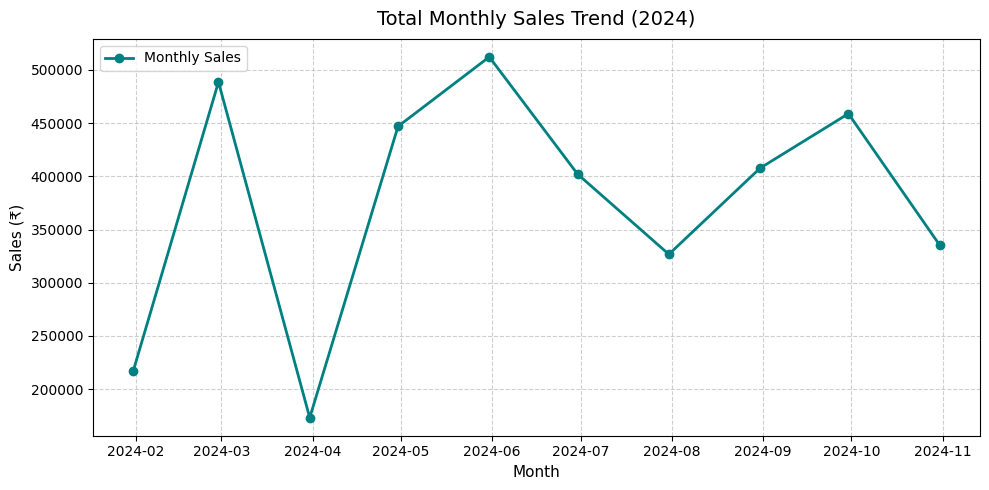

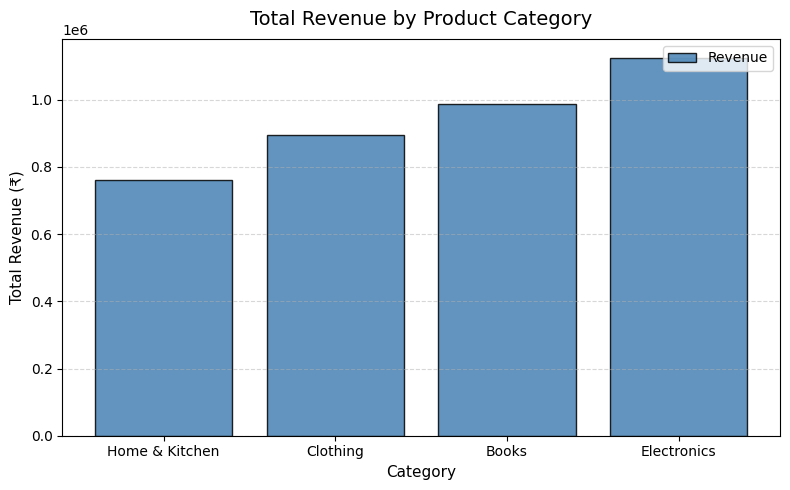

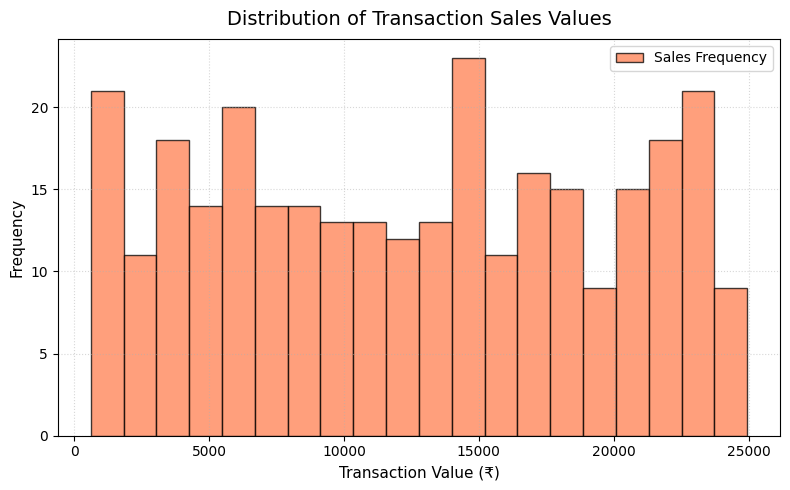

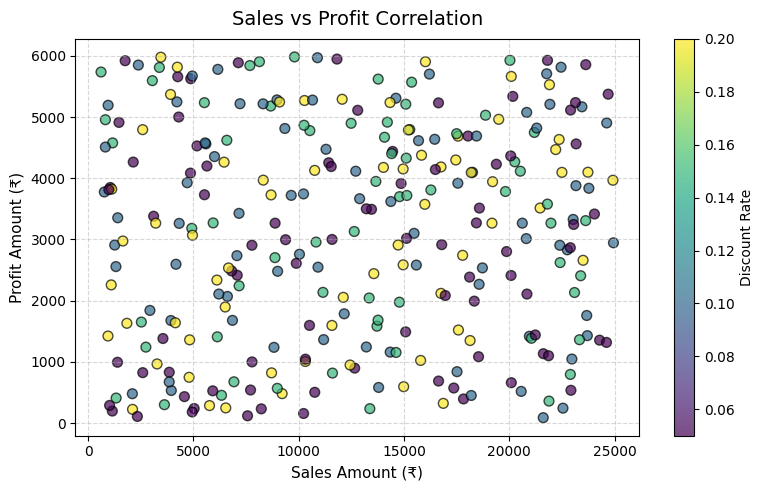

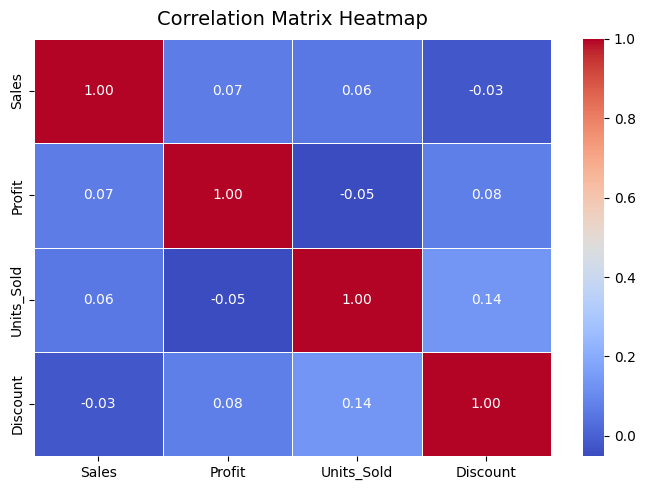

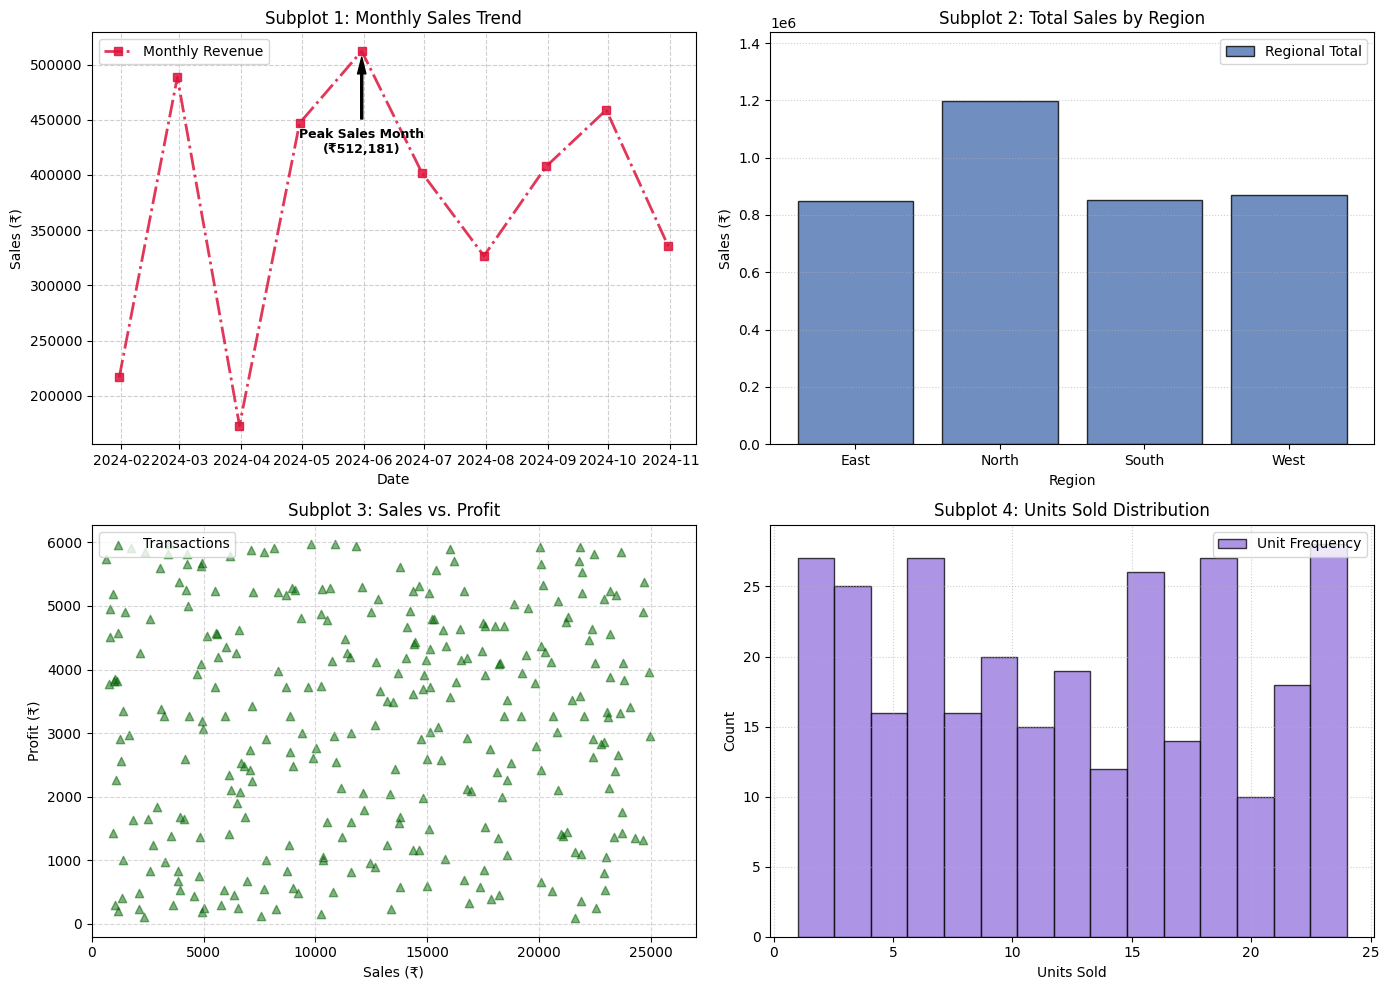

Complete dashboard executed and cleaned data exported successfully.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Set seed for reproducible synthetic data
np.random.seed(42)

# ==========================================================
# STEP 0: Generate Synthetic Dataset (to demonstrate loading & cleaning)
# ==========================================================
n_rows = 300
dates = pd.date_range(start="2024-01-01", periods=n_rows, freq="D")
categories = ["Electronics", "Clothing", "Home & Kitchen", "Books"]
regions = ["North", "South", "East", "West"]

raw_data = {
    "order_date": np.random.choice(dates.strftime("%Y-%m-%d"), size=n_rows),
    "prod_category": np.random.choice(categories, size=n_rows),
    "store_region": np.random.choice(regions, size=n_rows),
    "unit_sales": np.random.randint(1, 25, size=n_rows),
    "total_revenue": np.random.uniform(500, 25000, size=n_rows).round(2),
    "net_profit": np.random.uniform(50, 6000, size=n_rows).round(2),
    "discount_pct": np.random.choice([0.05, 0.10, 0.15, 0.20], size=n_rows),
}

df_raw = pd.DataFrame(raw_data)

# Introduce a few missing values and duplicates to demonstrate Task 3 cleaning
df_raw.loc[10:14, "net_profit"] = np.nan
df_raw = pd.concat([df_raw, df_raw.iloc[0:3]], ignore_index=True)
df_raw.to_csv("sales_dataset_raw.csv", index=False)


# ==========================================================
# Task 2: Data Loading and Basic Inspection
# ==========================================================
print("=" * 60)
print("TASK 2: DATA LOADING AND BASIC INSPECTION")
print("=" * 60)

# 1. Load dataset
df = pd.read_csv("sales_dataset_raw.csv")

# 2. Display first 5 rows
print("\n--- First 5 Rows ---")
print(df.head(5))

# 3. Display column names
print("\n--- Column Names ---")
print(list(df.columns))

# 4. Check missing values
print("\n--- Missing Values Count ---")
print(df.isnull().sum())

# 5. Display basic statistical summary
print("\n--- Statistical Summary ---")
print(df.describe())


# ==========================================================
# Task 3: Data Cleaning
# ==========================================================
print("\n" + "=" * 60)
print("TASK 3: DATA CLEANING")
print("=" * 60)

# 1. Handle missing values
df["net_profit"] = df["net_profit"].fillna(df["net_profit"].median())
print(
    f"Missing values handled. Remaining nulls: {df['net_profit'].isnull().sum()}"
)

# 2. Remove duplicate rows
before_dup = len(df)
df = df.drop_duplicates()
print(f"Removed {before_dup - len(df)} duplicate records.")

# 3. Rename columns
df = df.rename(
    columns={
        "order_date": "Date",
        "prod_category": "Category",
        "store_region": "Region",
        "unit_sales": "Units_Sold",
        "total_revenue": "Sales",
        "net_profit": "Profit",
        "discount_pct": "Discount",
    }
)
print("Columns renamed to clean title-case format.")

# 4. Convert date column to datetime
df["Date"] = pd.to_datetime(df["Date"])
print(f"Date column converted to type: {df['Date'].dtype}")

# 5. Sort dataset based on Date
df = df.sort_values(by="Date").reset_index(drop=True)
print("Dataset sorted chronologically by 'Date'.\n")


# ==========================================================
# Task 4: Create Visualizations (5 Charts with full formatting)
# ==========================================================

# 1. Line Chart: Monthly Sales Trend
monthly_sales = df.set_index("Date").resample("ME")["Sales"].sum()

plt.figure(figsize=(10, 5))
plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    color="teal",
    linestyle="-",
    marker="o",
    linewidth=2,
    label="Monthly Sales",
)
plt.title("Total Monthly Sales Trend (2024)", fontsize=14, pad=10)
plt.xlabel("Month", fontsize=11)
plt.ylabel("Sales (₹)", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

# 2. Bar Chart: Total Sales by Product Category
category_sales = df.groupby("Category")["Sales"].sum().sort_values()

plt.figure(figsize=(8, 5))
plt.bar(
    category_sales.index,
    category_sales.values,
    color="steelblue",
    edgecolor="black",
    alpha=0.85,
    label="Revenue",
)
plt.title("Total Revenue by Product Category", fontsize=14, pad=10)
plt.xlabel("Category", fontsize=11)
plt.ylabel("Total Revenue (₹)", fontsize=11)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

# 3. Histogram: Distribution of Sales Values
plt.figure(figsize=(8, 5))
plt.hist(
    df["Sales"],
    bins=20,
    color="coral",
    edgecolor="black",
    alpha=0.75,
    label="Sales Frequency",
)
plt.title("Distribution of Transaction Sales Values", fontsize=14, pad=10)
plt.xlabel("Transaction Value (₹)", fontsize=11)
plt.ylabel("Frequency", fontsize=11)
plt.grid(True, linestyle=":", alpha=0.5)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

# 4. Scatter Plot: Sales vs Profit with Discount alpha
plt.figure(figsize=(8, 5))
plt.scatter(
    df["Sales"],
    df["Profit"],
    c=df["Discount"],
    cmap="viridis",
    alpha=0.7,
    edgecolors="k",
    s=50,
)
cbar = plt.colorbar()
cbar.set_label("Discount Rate")
plt.title("Sales vs Profit Correlation", fontsize=14, pad=10)
plt.xlabel("Sales Amount (₹)", fontsize=11)
plt.ylabel("Profit Amount (₹)", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# 5. Heatmap: Correlation between numerical metrics
plt.figure(figsize=(7, 5))
num_corr = df[["Sales", "Profit", "Units_Sold", "Discount"]].corr()
sns.heatmap(num_corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix Heatmap", fontsize=14, pad=10)
plt.tight_layout()
plt.show()


# ==========================================================
# Tasks 5, 6, & 7: Subplots Dashboard with Styling and Annotations
# ==========================================================

# Task 5: Use plt.subplots() with 4 charts (2x2 grid)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# --- Subplot 1: Sales Trend with Task 7 Annotation ---
monthly_rev = df.set_index("Date").resample("ME")["Sales"].sum()
max_month = monthly_rev.idxmax()
max_sales = monthly_rev.max()

axes[0, 0].plot(
    monthly_rev.index,
    monthly_rev.values,
    color="crimson",  # Task 6: Line color
    linestyle="-.",  # Task 6: Line style
    marker="s",  # Task 6: Marker
    linewidth=2,
    alpha=0.85,  # Task 6: Transparency
    label="Monthly Revenue",
)
axes[0, 0].set_title(
    "Subplot 1: Monthly Sales Trend", fontsize=12
)  # Task 5: Individual title
axes[0, 0].set_xlabel("Date", fontsize=10)
axes[0, 0].set_ylabel("Sales (₹)", fontsize=10)
axes[0, 0].grid(True, linestyle="--", alpha=0.6)  # Task 6: Grid
axes[0, 0].legend(loc="upper left")  # Task 6: Legend location

# Task 7: Annotation highlighting peak sales month
axes[0, 0].annotate(
    f"Peak Sales Month\n(₹{max_sales:,.0f})",
    xy=(max_month, max_sales),
    xytext=(max_month, max_sales * 0.82),
    arrowprops=dict(facecolor="black", shrink=0.08, width=1.5, headwidth=6),
    fontsize=9,
    fontweight="bold",
    ha="center",
)

# --- Subplot 2: Region-wise Sales (Bar Chart) ---
region_data = df.groupby("Region")["Sales"].sum()
axes[0, 1].bar(
    region_data.index,
    region_data.values,
    color="#4C72B0",
    edgecolor="black",
    alpha=0.8,
    label="Regional Total",
)
axes[0, 1].set_title("Subplot 2: Total Sales by Region", fontsize=12)
axes[0, 1].set_xlabel("Region", fontsize=10)
axes[0, 1].set_ylabel("Sales (₹)", fontsize=10)
axes[0, 1].set_ylim(0, region_data.max() * 1.2)  # Task 6: Axis limits
axes[0, 1].grid(axis="y", linestyle=":", alpha=0.6)
axes[0, 1].legend(loc="upper right")

# --- Subplot 3: Sales vs Profit Scatter ---
axes[1, 0].scatter(
    df["Sales"],
    df["Profit"],
    color="darkgreen",
    marker="^",
    alpha=0.5,
    label="Transactions",
)
axes[1, 0].set_title("Subplot 3: Sales vs. Profit", fontsize=12)
axes[1, 0].set_xlabel("Sales (₹)", fontsize=10)
axes[1, 0].set_ylabel("Profit (₹)", fontsize=10)
axes[1, 0].set_xlim(0, 27000)  # Task 6: Axis limits
axes[1, 0].grid(True, linestyle="--", alpha=0.5)
axes[1, 0].legend(loc="upper left")

# --- Subplot 4: Units Sold Distribution (Histogram) ---
axes[1, 1].hist(
    df["Units_Sold"],
    bins=15,
    color="mediumpurple",
    edgecolor="black",
    alpha=0.75,
    label="Unit Frequency",
)
axes[1, 1].set_title("Subplot 4: Units Sold Distribution", fontsize=12)
axes[1, 1].set_xlabel("Units Sold", fontsize=10)
axes[1, 1].set_ylabel("Count", fontsize=10)
axes[1, 1].grid(True, linestyle=":", alpha=0.6)
axes[1, 1].legend(loc="upper right")

# Task 5: Proper spacing using plt.tight_layout()
plt.tight_layout()
plt.show()

# Export final cleaned dataset
df.to_csv("sales_dataset_cleaned.csv", index=False)
print("Complete dashboard executed and cleaned data exported successfully.")